# Лабораторна робота №1. Первинне дослідження джерел даних (CityFlow, S08)

**Студент:** Полянський Тимотей, група ФЕП-34, `student_id = S08`.
Блокнот лише **досліджує** сирі дані й нічого в них не виправляє: початкові CSV залишаються
незмінними в `data/raw/base_v1/`. Усі числа в звіті та документації беруться з виконання цього
блокнота (файли `docs/lab01/metrics.json`, `data_quality_findings.md`, `data_dictionary.md`
записуються в останніх комірках).

In [1]:
import json
import platform
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

try:
    from IPython.display import display
except ImportError:  # запуск як звичайного скрипта
    display = print


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Не знайдено корінь проєкту (pyproject.toml)")


ROOT = find_root()
RAW = ROOT / "data" / "raw" / "base_v1"
DOCS = ROOT / "docs" / "lab01"
DOCS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

print("Python", platform.python_version(), "| pandas", pd.__version__)

Python 3.14.7 | pandas 3.0.6


## 1. Пакет даних і контрольні суми
SHA-256 архіву звірено зі значенням викладача скриптом `scripts/prepare_raw.py`
(результат — `docs/package_checksums.json`). Тут додатково перевіряємо, що розпаковані файли
збігаються з `PACKAGE_INFO.json` пакета, тобто raw-дані не змінювалися.

In [2]:
package_info = json.loads((RAW / "PACKAGE_INFO.json").read_text(encoding="utf-8"))
checksums_path = ROOT / "docs" / "package_checksums.json"
checksums = json.loads(checksums_path.read_text(encoding="utf-8")) if checksums_path.exists() else {}

print("package_id:", package_info["package_id"], "| student_id:", package_info["student_id"])
for item in package_info["files"]:
    actual = hashlib.sha256((RAW / item["path"]).read_bytes()).hexdigest()
    status = "OK" if actual == item["sha256"] else "ЗМІНЕНО!"
    print(f"{item['path']:15} {actual[:16]}…  {status}")
    assert actual == item["sha256"], f"{item['path']} відрізняється від PACKAGE_INFO.json"
for name, info in checksums.get("archives", {}).items():
    print("архів", name, info["sha256"])

package_id: S08-LAB01-BASE-V1 | student_id: S08
README.txt      ae5b0de5a37815e6…  OK
customers.csv   51273484b70350ac…  OK
merchants.csv   2d3c403f6b594466…  OK
orders.csv      42547e7641607e97…  OK
products.csv    7ea189b9c7beb7e8…  OK
архів cityflow_S08_base_v1.zip 8a8eb3777248c41e1ffc424ca055ecde9ece81efe5a5e93e4d464bede4b661ac
архів cityflow_S08_lab02_relational_v1.zip a6f77a3ad9dcffb14a45440406be571b74051f14ed11d2372e62cdfac046a762


## 2. Зчитування та структура даних
Кожен файл читається двічі:
* `df[...]` — звичайний `pd.read_csv()` (типи визначає pandas, порожні поля стають `NaN`);
* `txt[...]` — той самий файл як текст (`dtype=str`, `keep_default_na=False`): так видно
  порожні рядки, рядки з пробілами та значення, які pandas мовчки перетворює.

**Що представляє рядок і які зв'язки очікуються**

| Файл | Один рядок = | Кандидатний ключ | Зв'язки |
|---|---|---|---|
| `customers.csv` | один клієнт | `customer_id` | батько для `orders.customer_id` |
| `merchants.csv` | один заклад-партнер | `merchant_id` | батько для `products.merchant_id` та `orders.merchant_id` |
| `products.csv` | один товар закладу | `product_id` | `merchant_id` → `merchants` |
| `orders.csv` | одне замовлення | `order_id` | `customer_id` → `customers`, `merchant_id` → `merchants` |

Унікальність кандидатних ключів нижче **перевіряється**, а не припускається.

In [3]:
SOURCES = {
    "customers": "customer_id",
    "merchants": "merchant_id",
    "products": "product_id",
    "orders": "order_id",
}
DATE_COL = {"customers": "registered_at", "merchants": "opened_at", "products": "updated_at", "orders": "created_at"}

df = {name: pd.read_csv(RAW / f"{name}.csv") for name in SOURCES}
txt = {name: pd.read_csv(RAW / f"{name}.csv", dtype=str, keep_default_na=False) for name in SOURCES}
for name, frame in df.items():
    print(f"{name:10} shape={frame.shape}")

customers  shape=(801, 8)
merchants  shape=(43, 7)
products   shape=(534, 7)
orders     shape=(6001, 10)


Для відтворюваності без raw-даних у Git зберігаємо **малі синтетичні вибірки** (перші 100 рядків
кожного файла) у `data/sample/lab01/`.

In [4]:
SAMPLE = ROOT / "data" / "sample" / "lab01"
SAMPLE.mkdir(parents=True, exist_ok=True)
for name, frame in df.items():
    frame.head(100).to_csv(SAMPLE / f"{name}_sample.csv", index=False)
print("Вибірки збережено в", SAMPLE.relative_to(ROOT))

Вибірки збережено в data/sample/lab01


### 2.1 customers

In [5]:
d = df["customers"]
display(d.head()); display(d.tail(3)); display(d.sample(3, random_state=8))
print("shape:", d.shape); print("columns:", list(d.columns)); print("index:", d.index)
print(d.dtypes); d.info()

,customer_id,full_name,email,phone,city,service_zone_id,registered_at,customer_status
0,S08-C000001,Natalia Shevchenko,s08.customer000001@example.test,3.805018e+11,Kharkiv,KHA-Z01,2026-01-24T23:51:01.642906949Z,active
1,S08-C000002,Mykhailo Tkachenko,s08.customer000002@example.test,3.806313e+11,Odesa,ODE-Z02,2025-01-23T12:21:14.546737732Z,active
2,S08-C000003,Olena Kuzmenko,s08.customer000003@example.test,3.806365e+11,Odesa,ODE-Z02,2025-02-28T03:46:17.772158405Z,active
3,S08-C000004,Vasyl Moroz,s08.customer000004@example.test,3.809583e+11,Lviv,LVI-Z02,2025-07-18T23:59:12.523425387Z,active
4,S08-C000005,Tetiana Havryliuk,s08.customer000005@example.test,3.806722e+11,Odesa,ODE-Z01,2025-06-19T00:59:09.116933694Z,active


,customer_id,full_name,email,phone,city,service_zone_id,registered_at,customer_status
798,S08-C000799,Bohdan Marchenko,s08.customer000799@example.test,3.809964e+11,Dnipro,DNI-Z01,2025-08-12T11:58:01.252875811Z,active
799,S08-C000800,Denys Kravets,s08.customer000800@example.test,3.809389e+11,Dnipro,DNI-Z03,2025-07-22T07:52:42.275820159Z,active
800,S08-C000504,Olena Koval,s08.customer000504@example.test,3.809382e+11,Lviv,LVI-Z02,2026-03-09T23:37:51.562482847Z,active


,customer_id,full_name,email,phone,city,service_zone_id,registered_at,customer_status
782,S08-C000783,Volodymyr Melnyk,s08.customer000783@example.test,3.809885e+11,Lviv,LVI-Z03,2025-04-25T08:23:08.094255924Z,active
696,S08-C000697,Solomiia Havryliuk,s08.customer000697@example.test,3.806372e+11,Dnipro,DNI-Z02,2025-01-11T17:16:02.794506924Z,active
223,S08-C000224,Iryna Polishchuk,s08.customer000224@example.test,3.806718e+11,Kharkiv,KHA-Z01,2025-06-02T22:30:41.444312221Z,active


shape: (801, 8)
columns: ['customer_id', 'full_name', 'email', 'phone', 'city', 'service_zone_id', 'registered_at', 'customer_status']
index: RangeIndex(start=0, stop=801, step=1)
customer_id            str
full_name              str
email                  str
phone              float64
city                   str
service_zone_id        str
registered_at          str
customer_status        str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 801 entries, 0 to 800
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      801 non-null    str    
 1   full_name        801 non-null    str    
 2   email            801 non-null    str    
 3   phone            796 non-null    float64
 4   city             801 non-null    str    
 5   service_zone_id  801 non-null    str    
 6   registered_at    801 non-null    str    
 7   customer_status  801 non-null    str    
dtypes: float64(1), str(7)
memory usa

**Пояснення.** 801 запис і 8 колонок. `phone` pandas прочитав як `float64`: усі непорожні значення —
цифри (знак `+` зникає), а порожні поля стали `NaN`. Телефон — це ідентифікатор, а не число для
усереднення, тому *тип pandas не відповідає змісту*. Дати (`registered_at`) прочитано як текст.

### 2.2 merchants

In [6]:
d = df["merchants"]
display(d.head()); display(d.tail(3)); display(d.sample(3, random_state=8))
print("shape:", d.shape); print("columns:", list(d.columns)); print("index:", d.index)
print(d.dtypes); d.info()

,merchant_id,merchant_name,merchant_type,city,service_zone_id,opened_at,merchant_status
0,S08-M00001,Family Table 01,restaurant,Dnipro,DNI-Z03,2024-07-18T04:35:38.016284212Z,active
1,S08-M00002,Craft Point 02,restaurant,Lviv,LVI-Z02,2024-10-26T09:28:20.916669749Z,active
2,S08-M00003,Morning Bread 03,bakery,Kyiv,KYI-Z02,2024-03-11T21:09:49.796490460Z,active
3,S08-M00004,Good Grocer 04,grocery,Lviv,LVI-Z01,2025-07-08T21:35:12.778932672Z,active
4,S08-M00005,Fresh Point 05,restaurant,Kyiv,KYI-Z02,2023-03-14T09:33:38.824646046Z,active


,merchant_id,merchant_name,merchant_type,city,service_zone_id,opened_at,merchant_status
40,S08-M00041,Family Bistro 41,restaurant,Kyiv,KYI-Z03,2021-01-29T06:18:48.490957540Z,active
41,S08-M00042,Craft Kitchen 42,restaurant,Odesa,ODE-Z02,2024-09-09T04:30:12.650188714Z,active
42,S08-M00009,Market Market 09,grocery,Kharkiv,KHA-Z03,2021-05-23T16:08:07.469483627Z,active


,merchant_id,merchant_name,merchant_type,city,service_zone_id,opened_at,merchant_status
38,S08-M00039,Warm Bread 39,bakery,Kyiv,KYI-Z01,2020-02-27T01:32:43.299764036Z,active
42,S08-M00009,Market Market 09,grocery,Kharkiv,KHA-Z03,2021-05-23T16:08:07.469483627Z,active
12,S08-M00013,Good Grocer 13,grocery,Kharkiv,KHA-Z01,2023-07-22T06:27:01.980054699Z,active


shape: (43, 7)
columns: ['merchant_id', 'merchant_name', 'merchant_type', 'city', 'service_zone_id', 'opened_at', 'merchant_status']
index: RangeIndex(start=0, stop=43, step=1)
merchant_id        str
merchant_name      str
merchant_type      str
city               str
service_zone_id    str
opened_at          str
merchant_status    str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   merchant_id      43 non-null     str  
 1   merchant_name    43 non-null     str  
 2   merchant_type    43 non-null     str  
 3   city             43 non-null     str  
 4   service_zone_id  43 non-null     str  
 5   opened_at        43 non-null     str  
 6   merchant_status  43 non-null     str  
dtypes: str(7)
memory usage: 2.5 KB


**Пояснення.** Довідник закладів: 43 записи, 7 колонок, пропусків немає. `opened_at` — текст,
який потрібно явно перетворювати на дату.

### 2.3 products

In [7]:
d = df["products"]
display(d.head()); display(d.tail(3)); display(d.sample(3, random_state=8))
print("shape:", d.shape); print("columns:", list(d.columns)); print("index:", d.index)
print(d.dtypes); d.info()

,product_id,merchant_id,product_name,category,unit_price_uah,is_active,updated_at
0,S08-P000001,S08-M00001,Chicken Burger,burgers,202.92,True,2025-10-19T02:50:44.689822020Z
1,S08-P000002,S08-M00001,Shrimp Set,sushi,251.88,True,2025-08-06T22:49:01.060705740Z
2,S08-P000003,S08-M00001,California Roll,sushi,476.03,True,2026-07-01T11:46:44.773195614Z
3,S08-P000004,S08-M00001,Cheesecake,desserts,180.08,True,2026-06-08T02:56:32.958552526Z
4,S08-P000005,S08-M00001,Salmon Roll,sushi,328.33,True,2026-07-26T20:59:40.586635704Z


,product_id,merchant_id,product_name,category,unit_price_uah,is_active,updated_at
531,S08-P000532,S08-M00042,Margherita,pizza,344.15,True,2026-01-15T19:51:11.646852793Z
532,S08-P000533,S08-M00042,Veggie Pizza,pizza,195.15,True,2026-01-01T01:41:28.305532753Z
533,S08-P000219,S08-M00018,Laundry Gel,household,272.33,True,2025-10-01T17:20:20.268416127Z


,product_id,merchant_id,product_name,category,unit_price_uah,is_active,updated_at
250,S08-P000251,S08-M00021,Kefir 1L,dairy,73.58,True,2025-11-13T21:44:08.010111348Z
318,S08-P000319,S08-M00026,Laundry Gel,household,61.20,False,2025-09-22T15:38:57.247427393Z
397,S08-P000398,S08-M00033,Collar,pet_accessories,185.64,True,2026-05-13T01:03:35.875385239Z


shape: (534, 7)
columns: ['product_id', 'merchant_id', 'product_name', 'category', 'unit_price_uah', 'is_active', 'updated_at']
index: RangeIndex(start=0, stop=534, step=1)
product_id            str
merchant_id           str
product_name          str
category              str
unit_price_uah    float64
is_active            bool
updated_at            str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 534 entries, 0 to 533
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      534 non-null    str    
 1   merchant_id     534 non-null    str    
 2   product_name    534 non-null    str    
 3   category        534 non-null    str    
 4   unit_price_uah  534 non-null    float64
 5   is_active       534 non-null    bool   
 6   updated_at      534 non-null    str    
dtypes: bool(1), float64(1), str(5)
memory usage: 25.7 KB


**Пояснення.** 534 товари, 7 колонок. `is_active` прочитано як `bool`, `unit_price_uah` як `float64`,
`updated_at` — як текст (у товарів **є** часове поле `updated_at`).

### 2.4 orders

In [8]:
d = df["orders"]
display(d.head()); display(d.tail(3)); display(d.sample(3, random_state=8))
print("shape:", d.shape); print("columns:", list(d.columns)); print("index:", d.index)
print(d.dtypes); d.info()

,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
0,S08-O0000001,S08-C000147,S08-M00030,2025-09-01T11:47:50Z,partially_refunded,UAH,196.55,86.22,19.66,263.11
1,S08-O0000002,S08-C000658,S08-M00023,2025-09-01T12:22:06Z,partially_refunded,UAH,1361.31,92.28,136.13,1317.46
2,S08-O0000003,S08-C000520,S08-M00005,2025-09-01T13:19:17Z,delivered,UAH,671.21,90.09,0.00,761.30
3,S08-O0000004,S08-C000038,S08-M00023,2025-09-01T13:20:44Z,delivered,UAH,802.25,72.11,0.00,874.36
4,S08-O0000005,S08-C000429,S08-M00020,2025-09-01T13:34:14Z,delivered,UAH,280.00,66.96,0.00,346.96


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
5998,S08-O0005999,S08-C000047,S08-M00040,2026-08-31T20:22:25Z,delivered,UAH,280.62,92.55,0.0,373.17
5999,S08-O0006000,S08-C000184,S08-M00009,2026-08-31T20:31:25Z,delivered,UAH,232.37,66.68,0.0,299.05
6000,S08-O0000683,S08-C000476,S08-M00024,2025-10-16T18:24:42Z,cancelled,UAH,668.45,72.32,0.0,740.77


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
5257,S08-O0005258,S08-C000415,S08-M00034,2026-07-15T11:11:54Z,delivered,UAH,192.64,84.87,19.26,258.25
1166,S08-O0001167,S08-C000528,S08-M00032,2025-11-12T10:53:24Z,cancelled,UAH,898.71,61.93,0.00,960.64
2125,S08-O0002126,S08-C000324,S08-M00012,2025-12-27T15:46:35Z,delivered,UAH,216.66,74.09,10.83,279.92


shape: (6001, 10)
columns: ['order_id', 'customer_id', 'merchant_id', 'created_at', 'order_status', 'currency', 'subtotal_amount', 'delivery_fee', 'discount_amount', 'total_amount']
index: RangeIndex(start=0, stop=6001, step=1)
order_id               str
customer_id            str
merchant_id            str
created_at             str
order_status           str
currency               str
subtotal_amount    float64
delivery_fee       float64
discount_amount    float64
total_amount       float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 6001 entries, 0 to 6000
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         6001 non-null   str    
 1   customer_id      6001 non-null   str    
 2   merchant_id      6001 non-null   str    
 3   created_at       6001 non-null   str    
 4   order_status     6001 non-null   str    
 5   currency         6001 non-null   str    
 6   subtotal_amount  60

**Пояснення.** 6001 запис, 10 колонок. Суми — `float64`. Валюта і статус — категоріальні тексти,
`created_at` — текст, що містить і коректні ISO-значення, і значення в інших форматах (див. розділ 5).

## 3. Первинне профілювання
### 3.1 Числові й категоріальні колонки: `describe()`, `nunique()`, `value_counts()`

In [9]:
for name, frame in df.items():
    print(f"\n=== {name} ===")
    display(frame.describe(include="all").T)
    display(frame.nunique().to_frame("nunique").T)
    for col in frame.columns:
        if frame[col].nunique() <= 12:
            print(f"\nvalue_counts: {name}.{col}")
            print(frame[col].value_counts(dropna=False).to_string())


=== customers ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,801,800,S08-C000504,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
full_name,801,501,Marko Tkachenko,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
email,801,799,s08.customer000277@example.test,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phone,796.0,NaN,NaN,NaN,380815712853.912048,167363391.740053,380500053852.0,380671054156.25,380931526894.5,380971016504.25,380999931260.0
city,801,6,Kyiv,234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_zone_id,801,18,LVI-Z01,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registered_at,801,800,2026-03-09T23:37:51.562482847Z,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_status,801,3,active,743,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,customer_id,full_name,email,phone,city,service_zone_id,registered_at,customer_status
nunique,800,501,799,795,6,18,800,3



value_counts: customers.city
city
Kyiv       234
Lviv       201
Odesa      135
Kharkiv    117
Dnipro     113
 Lviv        1

value_counts: customers.customer_status
customer_status
active       743
inactive      44
suspended     14

=== merchants ===


,count,unique,top,freq
merchant_id,43,42,S08-M00009,2
merchant_name,43,42,Market Market 09,2
merchant_type,43,7,restaurant,20
city,43,5,Kyiv,17
service_zone_id,43,16,KHA-Z01,5
opened_at,43,42,2021-05-23T16:08:07.469483627Z,2
merchant_status,43,3,active,41


,merchant_id,merchant_name,merchant_type,city,service_zone_id,opened_at,merchant_status
nunique,42,42,7,5,16,42,3


... (3 outputs left out)


value_counts: products.is_active
is_active
True     512
False     22

=== orders ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,6001,6000,S08-O0000683,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,6001,762,S08-C000280,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant_id,6001,42,S08-M00016,446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
created_at,6001,5997,2025-10-16T18:24:42Z,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_status,6001,6,delivered,4966,NaN,NaN,NaN,NaN,NaN,NaN,NaN
currency,6001,4,UAH,5928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subtotal_amount,6001.0,NaN,NaN,NaN,547.871698,432.97372,1.4,214.43,432.94,768.33,3033.61
delivery_fee,6001.0,NaN,NaN,NaN,72.954254,28.494591,0.0,69.63,79.12,89.1,148.88
discount_amount,6001.0,NaN,NaN,NaN,17.187265,39.662595,0.0,0.0,0.0,13.43,350.0
total_amount,6001.0,NaN,NaN,NaN,603.661548,409.483281,3.26,289.18,503.3,826.17,3102.01


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
nunique,6000,762,42,5997,6,4,5848,2418,1658,5848



value_counts: orders.order_status
order_status
delivered             4966
cancelled              449
partially_refunded     223
refunded               198
failed                 162
in_progress              3

value_counts: orders.currency
currency
UAH     5928
USD       40
EUR       32
UA H       1


Значення `value_counts` беруться з **початкових** даних, тому різні написання однієї категорії
(наприклад, місто з пробілами навколо) з'являються окремими рядками.

### 3.2 Пропуски, порожні рядки та рядки з пробілами
`NaN` у `df` — це порожнє поле CSV або явне «NA». У `txt` розрізняємо: порожнє поле (`""`),
рядок лише з пробілів та значення з пробілами по краях.

In [10]:
def missing_report(name: str) -> pd.DataFrame:
    t, f = txt[name], df[name]
    rows = []
    for col in t.columns:
        stripped = t[col].str.strip()
        rows.append({
            "column": col,
            "nan": int(f[col].isna().sum()),
            "nan_pct": round(float(f[col].isna().mean()) * 100, 2),
            "empty_field": int((t[col] == "").sum()),
            "whitespace_only": int(((stripped == "") & (t[col] != "")).sum()),
            "edge_whitespace": int(((t[col] != stripped) & (stripped != "")).sum()),
        })
    return pd.DataFrame(rows)


missing = {name: missing_report(name) for name in SOURCES}
for name, rep in missing.items():
    flagged = rep[(rep[["nan", "empty_field", "whitespace_only", "edge_whitespace"]] > 0).any(axis=1)]
    print(f"\n{name}: колонки з пропусками або пробілами ({len(flagged)} з {len(rep)})")
    display(flagged if len(flagged) else "немає")


customers: колонки з пропусками або пробілами (2 з 8)


,column,nan,nan_pct,empty_field,whitespace_only,edge_whitespace
3,phone,5,0.62,5,0,0
4,city,0,0.00,0,0,1



merchants: колонки з пропусками або пробілами (0 з 7)


'немає'


products: колонки з пропусками або пробілами (1 з 7)


,column,nan,nan_pct,empty_field,whitespace_only,edge_whitespace
3,category,0,0.0,0,0,1



orders: колонки з пропусками або пробілами (0 з 10)


'немає'

### 3.3 Повні дублікати та повторення кандидатного ключа

In [11]:
dup_info = {}
for name, key in SOURCES.items():
    frame = df[name]
    full = frame.duplicated(keep=False)
    key_dup = frame.duplicated(subset=[key], keep=False)
    conflicts = key_dup & ~full
    dup_info[name] = {
        "full_duplicate_rows": int(frame.duplicated().sum()),
        "key_repeat_rows": int(frame.duplicated(subset=[key]).sum()),
        "key_conflicts": int(conflicts.sum()),
        "ids": sorted(frame.loc[full, key].unique().tolist()),
    }
    print(f"{name:10} unique {key}: {frame[key].nunique()} з {len(frame)} рядків | {dup_info[name]}")
    if full.any():
        display(frame[full])

customers  unique customer_id: 800 з 801 рядків | {'full_duplicate_rows': 1, 'key_repeat_rows': 1, 'key_conflicts': 0, 'ids': ['S08-C000504']}


,customer_id,full_name,email,phone,city,service_zone_id,registered_at,customer_status
503,S08-C000504,Olena Koval,s08.customer000504@example.test,3.809382e+11,Lviv,LVI-Z02,2026-03-09T23:37:51.562482847Z,active
800,S08-C000504,Olena Koval,s08.customer000504@example.test,3.809382e+11,Lviv,LVI-Z02,2026-03-09T23:37:51.562482847Z,active


merchants  unique merchant_id: 42 з 43 рядків | {'full_duplicate_rows': 1, 'key_repeat_rows': 1, 'key_conflicts': 0, 'ids': ['S08-M00009']}


,merchant_id,merchant_name,merchant_type,city,service_zone_id,opened_at,merchant_status
8,S08-M00009,Market Market 09,grocery,Kharkiv,KHA-Z03,2021-05-23T16:08:07.469483627Z,active
42,S08-M00009,Market Market 09,grocery,Kharkiv,KHA-Z03,2021-05-23T16:08:07.469483627Z,active


products   unique product_id: 533 з 534 рядків | {'full_duplicate_rows': 1, 'key_repeat_rows': 1, 'key_conflicts': 0, 'ids': ['S08-P000219']}


,product_id,merchant_id,product_name,category,unit_price_uah,is_active,updated_at
218,S08-P000219,S08-M00018,Laundry Gel,household,272.33,True,2025-10-01T17:20:20.268416127Z
533,S08-P000219,S08-M00018,Laundry Gel,household,272.33,True,2025-10-01T17:20:20.268416127Z


orders     unique order_id: 6000 з 6001 рядків | {'full_duplicate_rows': 1, 'key_repeat_rows': 1, 'key_conflicts': 0, 'ids': ['S08-O0000683']}


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
682,S08-O0000683,S08-C000476,S08-M00024,2025-10-16T18:24:42Z,cancelled,UAH,668.45,72.32,0.0,740.77
6000,S08-O0000683,S08-C000476,S08-M00024,2025-10-16T18:24:42Z,cancelled,UAH,668.45,72.32,0.0,740.77


Усі повтори ключів є **повними** дублікатами (однакові всі колонки); конфліктів «той самий ключ,
різні значення» немає. Причину появи дублікатів джерело не пояснює, тому це лише спостереження.

### 3.4 Часовий діапазон: пропущені та некоректні дати
Дата вважається коректною, якщо відповідає ISO 8601 із `Z` або зсувом. Порожнє поле — *пропуск*;
непорожнє значення, що не розбирається, — *некоректна дата*. Початкові значення зберігаються.

In [12]:
date_info = {}
iso_dates = {}
for name in SOURCES:
    col = DATE_COL[name]
    raw_col = txt[name][col]
    parsed = pd.to_datetime(raw_col, format="ISO8601", errors="coerce", utc=True)
    empty = raw_col.str.strip() == ""
    invalid = parsed.isna() & ~empty
    iso_dates[name] = parsed
    date_info[name] = {
        "column": col,
        "min": str(parsed.min()), "max": str(parsed.max()),
        "missing": int(empty.sum()), "invalid": int(invalid.sum()),
        "invalid_rows": [
            {"id": txt[name].loc[i, SOURCES[name]], "value": raw_col.loc[i]} for i in invalid[invalid].index
        ],
    }
    print(f"{name:10} {col:14} min={parsed.min()}  max={parsed.max()}  пропущено={int(empty.sum())}  некоректних={int(invalid.sum())}")
    for row in date_info[name]["invalid_rows"]:
        print("    некоректне:", row)

customers  registered_at  min=2024-03-10 04:22:08.504394413+00:00  max=2026-08-29 07:06:33.137727612+00:00  пропущено=0  некоректних=0
merchants  opened_at      min=2019-09-07 11:46:11.601515588+00:00  max=2025-07-19 12:35:09.191823059+00:00  пропущено=0  некоректних=0
products   updated_at     min=2025-08-02 03:02:23.285140724+00:00  max=2026-08-30 23:59:20.250998490+00:00  пропущено=0  некоректних=0
orders     created_at     min=2025-09-01 11:47:50+00:00  max=2026-08-31 20:31:25+00:00  пропущено=0  некоректних=2
    некоректне: {'id': 'S08-O0000044', 'value': '04/09/2025 11:32'}
    некоректне: {'id': 'S08-O0003385', 'value': '2026-19-45 25:61:00'}


Два значення в `orders.created_at` не є ISO 8601. Одне (`04/09/2025 11:32`) має вигляд
`DD/MM/YYYY HH:MM` — **припущення**: це 4 вересня 2025 року, що вкладається в період пакета
(2025-09-01 … 2026-08-31), тоді як читання «місяць/день» дало б 9 квітня, поза періодом. Друге
(`2026-19-45 25:61:00`) неможливе за календарем. У цій роботі нічого не виправляємо; правила
приведення описано в Лабі 2.

### 3.5 Числові діапазони, нулі, від'ємні значення, категорії та коди валют

In [13]:
numeric_cols = {
    "products": ["unit_price_uah"],
    "orders": ["subtotal_amount", "delivery_fee", "discount_amount", "total_amount"],
}
numeric_info = {}
rows = []
for name, cols in numeric_cols.items():
    for col in cols:
        s = df[name][col]
        info = {"min": float(s.min()), "max": float(s.max()), "zero": int((s == 0).sum()), "negative": int((s < 0).sum())}
        numeric_info[f"{name}.{col}"] = info
        rows.append({"column": f"{name}.{col}", **info})
display(pd.DataFrame(rows))

products = df["products"]
zero_price = products[products["unit_price_uah"] <= 0]
print("\nТовари з ціною <= 0:")
display(zero_price)

ALLOWED_CURRENCY = {"UAH", "USD", "EUR"}
currency_counts = df["orders"]["currency"].value_counts(dropna=False).to_dict()
odd_currency = df["orders"][~df["orders"]["currency"].isin(ALLOWED_CURRENCY)]
print("\nКоди валют:", currency_counts)
display(odd_currency)

,column,min,max,zero,negative
0,products.unit_price_uah,0.00,760.46,1,0
1,orders.subtotal_amount,1.40,3033.61,0,0
2,orders.delivery_fee,0.00,148.88,614,0
3,orders.discount_amount,0.00,350.00,4203,0
4,orders.total_amount,3.26,3102.01,0,0



Товари з ціною <= 0:


,product_id,merchant_id,product_name,category,unit_price_uah,is_active,updated_at
73,S08-P000074,S08-M00006,Antiseptic,health,0.0,True,2026-08-09T04:27:35.239409173Z



Коди валют: {'UAH': 5928, 'USD': 40, 'EUR': 32, 'UA H': 1}


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
2448,S08-O0002449,S08-C000017,S08-M00042,2026-01-18T12:01:04Z,delivered,UA H,288.99,83.63,43.35,329.27


**Що потребує уточнення, а що — ні.** Нулі в `delivery_fee` і `discount_amount` — звичайні значення
(безкоштовна доставка, відсутність знижки); це не помилки. Нульова ціна **активного** товару
потребує бізнес-уточнення: за навчальним контрактом Лаби 2 вона недопустима, а для неактивного
товару нуль припустимий. Від'ємних сум немає. Код валюти `UA H` не належить до `UAH/USD/EUR` і
не виправляється здогадкою.

Додаткова діагностика сум замовлення (значення **не змінюються**): перевіряємо, чи виконується
`subtotal_amount + delivery_fee − discount_amount = total_amount`.

In [14]:
o = df["orders"]
diff = (o["subtotal_amount"] + o["delivery_fee"] - o["discount_amount"] - o["total_amount"]).round(2)
formula_bad = o.loc[diff.abs() > 0.01, ["order_id", "currency", "subtotal_amount", "delivery_fee", "discount_amount", "total_amount"]].copy()
formula_bad["difference"] = diff[diff.abs() > 0.01]
print("Замовлень, де формула не виконується:", len(formula_bad))
display(formula_bad)

Замовлень, де формула не виконується: 1


,order_id,currency,subtotal_amount,delivery_fee,discount_amount,total_amount,difference
1711,S08-O0001712,UAH,494.15,80.73,0.0,712.05,-137.17


### 3.6 Перевірка зв'язків між файлами

In [15]:
c, m, p = df["customers"], df["merchants"], df["products"]
orphan_orders_customer = o[~o["customer_id"].isin(c["customer_id"])]
orphan_orders_merchant = o[~o["merchant_id"].isin(m["merchant_id"])]
orphan_products_merchant = p[~p["merchant_id"].isin(m["merchant_id"])]
for title, frame in [
    ("orders.customer_id без запису в customers", orphan_orders_customer),
    ("orders.merchant_id без запису в merchants", orphan_orders_merchant),
    ("products.merchant_id без запису в merchants", orphan_products_merchant),
]:
    print(f"\n{title}: {len(frame)}")
    display(frame)


orders.customer_id без запису в customers: 1


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
4824,S08-O0004825,S08-C999999,S08-M00022,2026-06-20T15:21:26Z,delivered,UAH,43.21,63.19,0.0,106.4



orders.merchant_id без запису в merchants: 1


,order_id,customer_id,merchant_id,created_at,order_status,currency,subtotal_amount,delivery_fee,discount_amount,total_amount
5135,S08-O0005136,S08-C000119,S08-M99998,2026-07-08T11:53:47Z,delivered,UAH,823.97,65.07,0.0,889.04



products.merchant_id без запису в merchants: 1


,product_id,merchant_id,product_name,category,unit_price_uah,is_active,updated_at
330,S08-P000331,S08-M99999,Greek Yogurt,dairy,153.76,True,2026-01-07T02:26:28.876913511Z


## 4. Підсумкова таблиця
Тут **рахуються рядки файла** (разом із дублікатами); «унікальні ID» — кількість різних значень ключа.

In [16]:
summary_rows = []
for name, key in SOURCES.items():
    frame = df[name]
    summary_rows.append({
        "file": f"{name}.csv",
        "rows": len(frame),
        "columns": frame.shape[1],
        "unique_ids": int(frame[key].nunique()),
        "full_duplicates": int(frame.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
        "date_column": DATE_COL[name],
        "date_min": date_info[name]["min"],
        "date_max": date_info[name]["max"],
        "invalid_dates": date_info[name]["invalid"],
    })
summary = pd.DataFrame(summary_rows)
display(summary)

,file,rows,columns,unique_ids,full_duplicates,missing_cells,date_column,date_min,date_max,invalid_dates
0,customers.csv,801,8,800,1,5,registered_at,2024-03-10 04:22:08.504394413+00:00,2026-08-29 07:06:33.137727612+00:00,0
1,merchants.csv,43,7,42,1,0,opened_at,2019-09-07 11:46:11.601515588+00:00,2025-07-19 12:35:09.191823059+00:00,0
2,products.csv,534,7,533,1,0,updated_at,2025-08-02 03:02:23.285140724+00:00,2026-08-30 23:59:20.250998490+00:00,0
3,orders.csv,6001,10,6000,1,0,created_at,2025-09-01 11:47:50+00:00,2026-08-31 20:31:25+00:00,2


## 5. Діагностичні графіки
Це підрахунки **записів** (разом із повними дублікатами), а не перевірені бізнес-показники;
суми різних валют не об'єднуються.

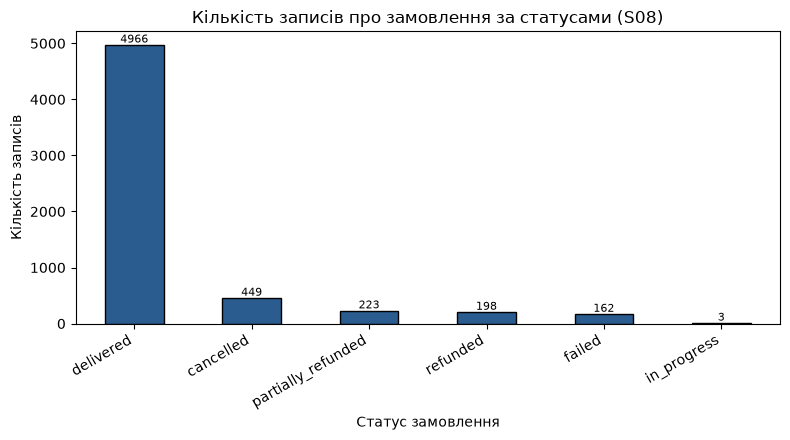

In [17]:
status_counts = o["order_status"].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
status_counts.plot(kind="bar", color="#2b5c8f", edgecolor="black", ax=ax)
ax.set_title("Кількість записів про замовлення за статусами (S08)")
ax.set_xlabel("Статус замовлення")
ax.set_ylabel("Кількість записів")
for i, value in enumerate(status_counts.values):
    ax.text(i, value, str(int(value)), ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(DOCS / "orders_by_status.png", dpi=200)
plt.show()

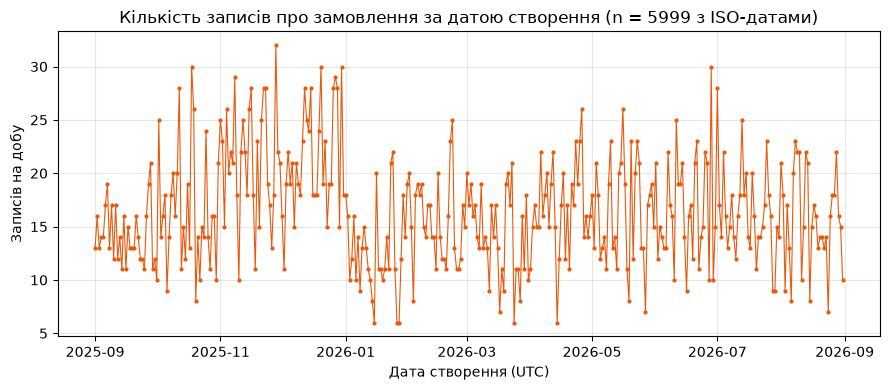

{'days': 365, 'min': 6, 'max': 32, 'median': 16.0, 'mean': 16.4, 'min_day': '2026-01-15', 'max_day': '2025-11-28', 'excluded_non_iso': 2, 'kyiv_min': 5, 'kyiv_max': 32, 'high_month': '2025-11', 'high_month_mean': 21.3, 'low_month': '2026-01', 'low_month_mean': 12.8}


In [18]:
dates = iso_dates["orders"].dropna()
daily = dates.dt.date.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pd.to_datetime(daily.index), daily.values, color="#e8590c", marker="o", markersize=2, linewidth=0.8)
ax.set_title(f"Кількість записів про замовлення за датою створення (n = {len(dates)} з ISO-датами)")
ax.set_xlabel("Дата створення (UTC)")
ax.set_ylabel("Записів на добу")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(DOCS / "orders_by_date.png", dpi=200)
plt.show()
daily_stats = {
    "days": int(len(daily)), "min": int(daily.min()), "max": int(daily.max()),
    "median": float(daily.median()), "mean": round(float(daily.mean()), 1),
    "min_day": str(daily.idxmin()), "max_day": str(daily.idxmax()),
    "excluded_non_iso": int(date_info["orders"]["invalid"]),
}
# The same counts by local Kyiv date: day boundaries move, so min/max may differ from UTC.
daily_kyiv = dates.dt.tz_convert("Europe/Kyiv").dt.date.value_counts()
daily_stats.update({"kyiv_min": int(daily_kyiv.min()), "kyiv_max": int(daily_kyiv.max())})
monthly = daily.groupby(pd.to_datetime(daily.index).to_period("M")).mean()
daily_stats.update({
    "high_month": str(monthly.idxmax()), "high_month_mean": round(float(monthly.max()), 1),
    "low_month": str(monthly.idxmin()), "low_month_mean": round(float(monthly.min()), 1),
})
print(daily_stats)

**Висновок за графіками.** Серед записів переважає статус `delivered`; активних (`in_progress`)
лише кілька. Добова кількість записів коливається в діапазоні, наведеному вище; медіана ближча до
середнього, ніж до екстремумів. Окремі добові піки й провали **не пояснюються** даними пакета —
це спостереження, а не підтверджений висновок. Два записи з не-ISO датою на графік дат не потрапили.

## 6. Реєстр проблем якості
Реєстр формується **з обчислених вище результатів** (жодного вручну вписаного ID): якщо певної
проблеми в пакеті немає, рядка в реєстрі немає.

In [19]:
findings = []


def add(file, field, kind, problem, count, ids, impact, action, targets=None):
    findings.append({
        "file": file, "field": field, "kind": kind, "problem": problem, "count": int(count),
        "ids": list(ids), "impact": impact, "action": action,
        "targets": targets or [file.replace(".csv", "")],
    })


CONF, RISK = "підтверджене порушення", "потенційний ризик"

dups = {n: i for n, i in dup_info.items() if i["full_duplicate_rows"] > 0}
if dups:
    add("усі 4 CSV" if len(dups) == 4 else ", ".join(f"{n}.csv" for n in dups), "ключ рядка", CONF,
        "повні дублікати рядків", sum(i["full_duplicate_rows"] for i in dups.values()),
        [x for i in dups.values() for x in i["ids"]],
        "подвоєння записів; порушення PK у реляційній базі",
        "залишити одну точну копію, решту позначити як duplicate (Лаба 2)", targets=list(dups))

phone_missing = txt["customers"].loc[txt["customers"]["phone"] == "", "customer_id"].tolist()
if phone_missing:
    add("customers.csv", "phone", RISK, "порожнє поле телефону", len(phone_missing), phone_missing,
        "немає контакту для зв'язку; чи є телефон обов'язковим — припущення, джерело цього не каже",
        "прийняти як допустимий пропуск, не підставляти 0 чи сурогат")

for name in SOURCES:
    for _, rep_row in missing[name].iterrows():
        if rep_row["edge_whitespace"] > 0:
            t = txt[name]
            col = rep_row["column"]
            bad = t.loc[(t[col] != t[col].str.strip()) & (t[col].str.strip() != ""), SOURCES[name]].tolist()
            add(f"{name}.csv", col, CONF, "пробіли на початку/в кінці значення", len(bad), bad,
                "окремі написання однієї категорії (' Lviv ' ≠ 'Lviv') ламають групування та порівняння",
                "обрізати пробіли за явним правилом нормалізації, оригінал зберегти")

if len(zero_price):
    active_zero = zero_price[zero_price["is_active"]]
    add("products.csv", "unit_price_uah", RISK, "ціна ≤ 0 в активного товару" if len(active_zero) else "ціна ≤ 0 в неактивного товару",
        len(zero_price), zero_price["product_id"].tolist(),
        "потребує бізнес-уточнення; нуль не завжди помилка (для неактивного товару допустимий)",
        "за контрактом Лаби 2 активний товар із ціною ≤ 0 відхиляється")

if len(orphan_products_merchant):
    add("products.csv", "merchant_id", CONF, "посилання на відсутнього партнера", len(orphan_products_merchant),
        orphan_products_merchant["product_id"].tolist(), "порушення FK; INNER JOIN мовчки втратить товар",
        "карантин з причиною ORPHAN_MERCHANT_FK")
if len(orphan_orders_customer):
    add("orders.csv", "customer_id", CONF, "посилання на відсутнього клієнта", len(orphan_orders_customer),
        orphan_orders_customer["order_id"].tolist(), "порушення FK; замовлення випаде зі звітів при INNER JOIN",
        "карантин з причиною ORPHAN_CUSTOMER_FK")
if len(orphan_orders_merchant):
    add("orders.csv", "merchant_id", CONF, "посилання на відсутнього партнера", len(orphan_orders_merchant),
        orphan_orders_merchant["order_id"].tolist(), "порушення FK", "карантин з причиною ORPHAN_MERCHANT_FK")

if len(odd_currency):
    add("orders.csv", "currency", CONF, "код валюти поза UAH/USD/EUR: " + ", ".join(f"'{v}'" for v in odd_currency["currency"].unique()),
        len(odd_currency), odd_currency["order_id"].tolist(), "розбиття групування за валютою; суми різних валют не можна об'єднувати",
        "не виправляти здогадкою; відхиляти з причиною INVALID_CURRENCY")

bad_dates = date_info["orders"]["invalid_rows"]
if bad_dates:
    add("orders.csv", "created_at", CONF, "значення не є ISO 8601: " + "; ".join(f"'{r['value']}'" for r in bad_dates),
        len(bad_dates), [r["id"] for r in bad_dates],
        "не приводяться до timestamptz автоматично; формат DD/MM/YYYY — лише припущення",
        "DD/MM/YYYY HH:MM явно читати як UTC, неможливі дати відхиляти (Лаба 2)")

if len(formula_bad):
    add("orders.csv", "total_amount", RISK, "subtotal + delivery_fee − discount ≠ total_amount", len(formula_bad),
        formula_bad["order_id"].tolist(),
        "total_amount " + ", ".join(("більший" if x < 0 else "менший") + f" за обчислений на {abs(x):.2f}" for x in formula_bad["difference"]) + "; причина невідома",
        "лише діагностика, значення джерела не переписувати")

print(f"Записів у реєстрі: {len(findings)}")
display(pd.DataFrame([{k: (", ".join(v[:3]) + ("…" if len(v) > 3 else "") if k == "ids" else v) for k, v in f.items()} for f in findings]))

Записів у реєстрі: 11


,file,field,kind,problem,count,ids,impact,action,targets
0,усі 4 CSV,ключ рядка,підтверджене порушення,повні дублікати рядків,4,"S08-C000504, S08-M00009, S08-P000219…",подвоєння записів; порушення PK у реляційній базі,"залишити одну точну копію, решту позначити як ...","[customers, merchants, products, orders]"
1,customers.csv,phone,потенційний ризик,порожнє поле телефону,5,"S08-C000179, S08-C000180, S08-C000254…",немає контакту для зв'язку; чи є телефон обов'...,"прийняти як допустимий пропуск, не підставляти...",[customers]
2,customers.csv,city,підтверджене порушення,пробіли на початку/в кінці значення,1,S08-C000727,окремі написання однієї категорії (' Lviv ' ≠ ...,обрізати пробіли за явним правилом нормалізаці...,[customers]
3,products.csv,category,підтверджене порушення,пробіли на початку/в кінці значення,1,S08-P000195,окремі написання однієї категорії (' Lviv ' ≠ ...,обрізати пробіли за явним правилом нормалізаці...,[products]
4,products.csv,unit_price_uah,потенційний ризик,ціна ≤ 0 в активного товару,1,S08-P000074,потребує бізнес-уточнення; нуль не завжди поми...,за контрактом Лаби 2 активний товар із ціною ≤...,[products]
5,products.csv,merchant_id,підтверджене порушення,посилання на відсутнього партнера,1,S08-P000331,порушення FK; INNER JOIN мовчки втратить товар,карантин з причиною ORPHAN_MERCHANT_FK,[products]
6,orders.csv,customer_id,підтверджене порушення,посилання на відсутнього клієнта,1,S08-O0004825,порушення FK; замовлення випаде зі звітів при ...,карантин з причиною ORPHAN_CUSTOMER_FK,[orders]
7,orders.csv,merchant_id,підтверджене порушення,посилання на відсутнього партнера,1,S08-O0005136,порушення FK,карантин з причиною ORPHAN_MERCHANT_FK,[orders]
8,orders.csv,currency,підтверджене порушення,код валюти поза UAH/USD/EUR: 'UA H',1,S08-O0002449,розбиття групування за валютою; суми різних ва...,не виправляти здогадкою; відхиляти з причиною ...,[orders]
9,orders.csv,created_at,підтверджене порушення,значення не є ISO 8601: '04/09/2025 11:32'; '2...,2,"S08-O0000044, S08-O0003385",не приводяться до timestamptz автоматично; фор...,"DD/MM/YYYY HH:MM явно читати як UTC, неможливі...",[orders]


## 7. Запис документації: реєстр проблем, словник даних, метрики

In [20]:
def short_ids(ids, limit=4):
    return ", ".join(f"`{i}`" for i in ids[:limit]) + (f" … (усього {len(ids)})" if len(ids) > limit else "")


lines = ["# Реєстр проблем якості даних (CityFlow S08)", "",
         f"Пакет: `{package_info['package_id']}` (student_id `{package_info['student_id']}`). "
         "Згенеровано блокнотом `notebooks/lab01/01_source_profiling.py`; числа обчислені, а не вписані вручну.",
         "", "| № | Файл / поле | Тип | Проблема | К-сть | Приклади ID | Можливий вплив | Запропонована дія |",
         "|---|---|---|---|---|---|---|---|"]
for i, f in enumerate(findings, 1):
    lines.append(f"| {i} | `{f['file']}` / `{f['field']}` | {f['kind']} | {f['problem']} | {f['count']} | "
                 f"{short_ids(f['ids'])} | {f['impact']} | {f['action']} |")
lines += ["", "*Підтверджене порушення* — значення суперечить правилу, яке видно з самих даних. "
          "*Потенційний ризик* — потребує бізнес-уточнення; будь-яке припущення позначено прямо."]
(DOCS / "data_quality_findings.md").write_text("\n".join(lines) + "\n", encoding="utf-8")

3318

In [21]:
META = {
    "customers": ("Клієнти сервісу.", "один клієнт", {
        "customer_id": ("text", "ідентифікатор клієнта", "PK (кандидат)", "ні"),
        "full_name": ("text", "ім'я клієнта", "—", "ні"),
        "email": ("text", "електронна пошта; унікальність не підтверджена правилом (припущення)", "—", "ні"),
        "phone": ("text", "телефон; обов'язковість не підтверджена (припущення)", "—", "так"),
        "city": ("text", "місто", "—", "ні"),
        "service_zone_id": ("text", "код зони обслуговування (припущення: довідник service_zones з Лаби 2)", "FK? (припущення)", "ні"),
        "registered_at": ("timestamptz", "момент реєстрації", "—", "ні"),
        "customer_status": ("text", "статус клієнта", "—", "ні"),
    }),
    "merchants": ("Партнерські заклади.", "один заклад", {
        "merchant_id": ("text", "ідентифікатор закладу", "PK (кандидат)", "ні"),
        "merchant_name": ("text", "назва закладу", "—", "ні"),
        "merchant_type": ("text", "тип закладу", "—", "ні"),
        "city": ("text", "місто", "—", "ні"),
        "service_zone_id": ("text", "код зони обслуговування (припущення: довідник service_zones)", "FK? (припущення)", "ні"),
        "opened_at": ("timestamptz", "момент відкриття закладу", "—", "ні"),
        "merchant_status": ("text", "статус закладу", "—", "ні"),
    }),
    "products": ("Товари партнерів.", "один товар закладу", {
        "product_id": ("text", "ідентифікатор товару", "PK (кандидат)", "ні"),
        "merchant_id": ("text", "заклад-власник товару", "FK → merchants.merchant_id", "ні"),
        "product_name": ("text", "назва товару", "—", "ні"),
        "category": ("text", "категорія товару", "—", "ні"),
        "unit_price_uah": ("numeric(12,2)", "поточна ціна одиниці в UAH (не історична ціна замовлення)", "—", "ні"),
        "is_active": ("boolean", "чи товар активний", "—", "ні"),
        "updated_at": ("timestamptz", "момент останнього оновлення запису", "—", "ні"),
    }),
    "orders": ("Замовлення клієнтів.", "одне замовлення", {
        "order_id": ("text", "ідентифікатор замовлення", "PK (кандидат)", "ні"),
        "customer_id": ("text", "клієнт", "FK → customers.customer_id", "ні"),
        "merchant_id": ("text", "заклад", "FK → merchants.merchant_id", "ні"),
        "created_at": ("timestamptz", "момент створення замовлення", "—", "ні"),
        "order_status": ("text", "статус замовлення", "—", "ні"),
        "currency": ("text", "код валюти замовлення (очікувано UAH/USD/EUR — припущення)", "—", "ні"),
        "subtotal_amount": ("numeric(12,2)", "сума позицій до знижки та доставки (у валюті замовлення)", "—", "ні"),
        "delivery_fee": ("numeric(12,2)", "вартість доставки; 0 — звичайне значення", "—", "ні"),
        "discount_amount": ("numeric(12,2)", "знижка на замовлення; 0 — звичайне значення", "—", "ні"),
        "total_amount": ("numeric(12,2)", "підсумкова сума (не дорівнює чистому виторгу)", "—", "ні"),
    }),
}
problems = {}
for f in findings:
    for t in f["targets"]:
        is_key_finding = f["field"] == "ключ рядка"
        col = SOURCES[t] if is_key_finding else f["field"]
        ids = dup_info[t]["ids"] if is_key_finding else f["ids"]
        problems.setdefault((t, col), []).append(f"{f['problem']}: {short_ids(ids, 2)}")

out = ["# Словник даних CityFlow (пакет S08)", "",
       "Типи pandas і приклади взято з виконання блокнота. Логічні типи, зміст і обов'язковість, які "
       "не підтверджені джерелом, позначені як *припущення*.", ""]
for name, (about, grain, cols) in META.items():
    frame = df[name]
    out += [f"## `{name}.csv`", f"{about} **Один рядок =** {grain}. Рядків: {len(frame)}.", "",
            "| Колонка | Тип pandas | Логічний тип | Зміст | Роль ключа | NULL | Приклад | Виявлені проблеми |",
            "|---|---|---|---|---|---|---|---|"]
    for col, (logical, meaning, role, nullable) in cols.items():
        example = txt[name][col].replace("", pd.NA).dropna().iloc[0]
        issues = "; ".join(problems.get((name, col), [])) or "не виявлено"
        out.append(f"| `{col}` | `{frame[col].dtype}` | `{logical}` | {meaning} | {role} | {nullable} | `{example}` | {issues} |")
    out.append("")
(DOCS / "data_dictionary.md").write_text("\n".join(out), encoding="utf-8")

5260

In [22]:
metrics = {
    "student_id": package_info["student_id"],
    "package_id": package_info["package_id"],
    "python": platform.python_version(),
    "pandas": pd.__version__,
    "archives": checksums.get("archives", {}),
    "summary": summary_rows,
    "statuses": {k: int(v) for k, v in status_counts.items()},
    "currencies": {k: int(v) for k, v in currency_counts.items()},
    "daily": daily_stats,
    "dups": dup_info,
    "missing_phone": phone_missing,
    "zero_price": zero_price.astype(str).to_dict("records"),
    "formula_bad": formula_bad.astype(str).to_dict("records"),
    "date_info": {n: {k: v for k, v in i.items()} for n, i in date_info.items()},
    "missing": [
        {"file": f"{n}.csv", **{k: (v if k == "column" else int(v)) for k, v in row.items() if k != "nan_pct"}}
        for n, rep in missing.items() for row in rep.to_dict("records")
        if row["nan"] or row["empty_field"] or row["whitespace_only"] or row["edge_whitespace"]
    ],
    "numeric": numeric_info,
    "orphans": {
        "orders.customer_id": orphan_orders_customer["order_id"].tolist(),
        "orders.merchant_id": orphan_orders_merchant["order_id"].tolist(),
        "products.merchant_id": orphan_products_merchant["product_id"].tolist(),
    },
    "findings": findings,
}
(DOCS / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print("Записано docs/lab01/: metrics.json, data_quality_findings.md, data_dictionary.md, orders_by_*.png")

Записано docs/lab01/: metrics.json, data_quality_findings.md, data_dictionary.md, orders_by_*.png
